# Controlled simulation

Integrate prepared RNA–ATAC inputs with MELON, predict the biological targets, and evaluate performance.

The functions show the computation at each stage. The following cells continue from the supplied intermediate files, so training and clustering are not repeated. Start with prepared modality features; see the [Tutorials](https://txbrook.github.io/MELON_website/tutorials/) for preprocessing.

In [1]:
from pathlib import Path
import os, sys
import numpy as np
import pandas as pd
from IPython.display import display

repo = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "Reproduce").is_dir())
sys.path.insert(0, str(repo / "Reproduce"))
from _shared.paper_plots import *
from _shared.workflow import assay_shape, align_partition
DATA_ROOT = Path(os.environ.get("MELON_PUBLISHED_DATA", repo / "Published_Data_non_NASH"))
DATA = DATA_ROOT / "06_Controlled_simulation"
assert DATA.is_dir(), "Place Published_Data_non_NASH beside Reproduce, or set MELON_PUBLISHED_DATA."

## 1. Assemble the paired modalities and prediction targets

Each seed supplies a 44 × 44 spatial grid, two 600-feature modality matrices and the R/U/C/Y targets. The input matrices have already undergone log1p transformation.

In [2]:
seeds = [123, 124, 125]
datasets = {}
for seed in seeds:
    folder = DATA / f"02_model_inputs/seed{seed}"
    rna = np.load(folder / "X_rna.npy", mmap_mode="r")
    atac = np.load(folder / "X_atac.npy", mmap_mode="r")
    meta = pd.read_csv(folder / "meta.csv", dtype={"spot_id": str}).set_index("spot_id")
    coordinates = meta[["x", "y"]]
    targets = meta[["R", "U", "C", "Y"]]
    assert len(rna) == len(atac) == len(meta)
    datasets[seed] = (rna, atac, coordinates, targets)
display({seed: {"RNA": pair[0].shape, "ATAC": pair[1].shape} for seed, pair in datasets.items()})

{123: {'RNA': (1936, 600), 'ATAC': (1936, 600)},
 124: {'RNA': (1936, 600), 'ATAC': (1936, 600)},
 125: {'RNA': (1936, 600), 'ATAC': (1936, 600)}}

## 2. Configure and train MELON

The simulation configuration uses 20 epochs, a 256-dimensional representation, spatial k = 4, augmentation probability 0.3 and learning rate 0.002. The augmentation views use Gaussian noise and feature dropout. Each dataset seed is also its model seed.

Edit the configuration cell below to adjust the model parameters.

In [3]:
# Edit the parameters here.
config = {
    'epochs': 20,
    'batch_size': 2048,
    'embed_dim': 256,
    'training_seed': 123,
    'learning_rate': 0.002,
    'weight_decay': 1e-05,
    'temperature': 0.1,
    'training_spatial_k': 4,
    'export_spatial_k': None,
    'augment_p': 0.3,
    'augmentations': ['gaussian_noise', 'feature_dropout'],
    'shuffle_batches': False,
    'historical_five_modal': False,
}

In [4]:
def integrate_modalities(features, coordinates, config):
    """Learn a joint representation from aligned, preprocessed modality arrays."""
    import torch
    import pytorch_lightning as pl
    from _shared.engine import make_model, export_embedding, PaperAugmentations
    from _shared.publication_model.data import DualAugDataModule, SpatialOmicsAugmentations
    from _shared.publication_model.utils import build_knn_mask

    pl.seed_everything(config["training_seed"], workers=True)
    tensors = [torch.as_tensor(x, dtype=torch.float32) for x in features]
    xy = torch.as_tensor(coordinates.to_numpy(), dtype=torch.float32)
    mask, weight = build_knn_mask(xy, k=config["training_spatial_k"],
                                  include_self=True, return_weights=True)
    augmentation = SpatialOmicsAugmentations if config["historical_five_modal"] else PaperAugmentations
    aug = dict(augmentations=config.get("augmentations", ["gaussian_noise", "feature_dropout", "neighbor_mix"]),
               p=config["augment_p"])
    data = DualAugDataModule(
        mods_raw=tensors, coords=xy, neighbor_mask=mask, neighbor_weight=weight,
        batch_size=config["batch_size"], augmentA=augmentation(**aug), augmentB=augmentation(**aug),
        spot_tokenization=True, shuffle=config["shuffle_batches"])
    model = make_model([x.shape[1] for x in features], config)
    trainer = pl.Trainer(max_epochs=config["epochs"], accelerator="cpu", devices=1,
                         logger=False, enable_checkpointing=False, deterministic=True)
    trainer.fit(model, datamodule=data)
    z = export_embedding(model, tensors, xy, config["export_spatial_k"])
    return pd.DataFrame(z, index=coordinates.index)

In [5]:
embeddings = {}
for seed, (rna, atac, coordinates, targets) in datasets.items():
    parameters = dict(config, training_seed=seed)
    # MELON maps the two modality arrays to a joint representation.
    z = read_indexed(DATA / f"03_embeddings/seed{seed}/MELON.csv")
    embeddings[seed] = align_embedding(z, coordinates)
display({seed: z.shape for seed, z in embeddings.items()})

{123: (1936, 256), 124: (1936, 256), 125: (1936, 256)}

## 3. Predict the biological targets

Evaluate Y with an MLP and R/U/C with linear SVMs using five stratified folds. Feature standardization is fitted within each training fold. The function below specifies the prediction procedure; the evaluation node provides its completed summary.

In [6]:
def evaluate_targets(embedding, targets, seed):
    from sklearn.model_selection import StratifiedKFold
    from sklearn.pipeline import make_pipeline
    from sklearn.preprocessing import StandardScaler
    from sklearn.neural_network import MLPClassifier
    from sklearn.svm import LinearSVC
    from sklearn.metrics import balanced_accuracy_score

    x = embedding.to_numpy()
    rows = []
    for target in ["R", "U", "C", "Y"]:
        y = targets.loc[embedding.index, target].to_numpy()
        folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)
        for fold, (train, test) in enumerate(folds.split(x, y), start=1):
            if target == "Y":
                estimator = MLPClassifier(hidden_layer_sizes=(128,), alpha=1e-4,
                    learning_rate_init=1e-3, early_stopping=True, max_iter=400,
                    n_iter_no_change=20, random_state=seed + fold)
            else:
                estimator = LinearSVC(class_weight="balanced", max_iter=5000, random_state=seed + fold)
            probe = make_pipeline(StandardScaler(), estimator)
            probe.fit(x[train], y[train])
            rows.append({"seed": seed, "target": target, "fold": fold,
                         "balanced_accuracy": balanced_accuracy_score(y[test], probe.predict(x[test]))})
    return pd.DataFrame(rows)

evaluation = pd.read_csv(DATA / "04_saved_evaluation/MELON_summary.csv")
scores = simulation_scores(evaluation)

## 4. Summarize prediction performance

Bars show mean balanced accuracy across the three seeds, with standard-deviation error bars.

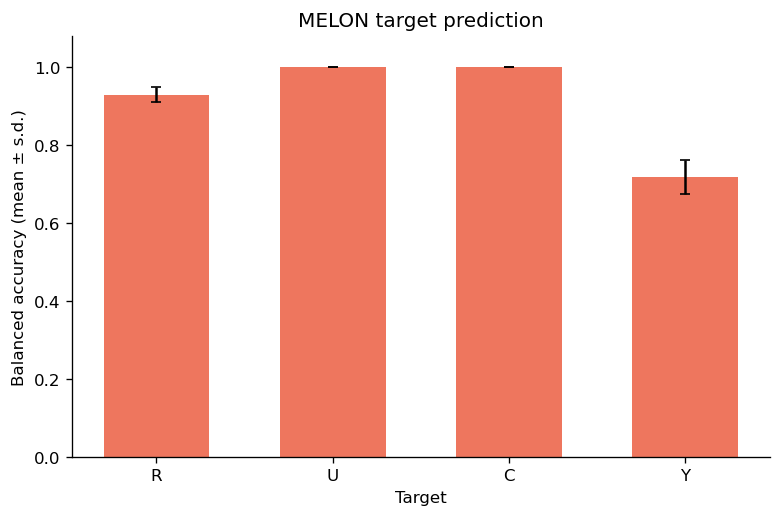

In [7]:
show(simulation_score_panels(scores))